# Câu 3: Đánh giá mô hình được chọn trên tập Test độc lập & Phân tích lỗi

**Mục tiêu:**
1. Đánh giá mô hình chốt (`models/best_model.joblib` + `models/threshold.json`) **một lần duy nhất** trên tập kiểm tra độc lập `data/splits/test.csv` ($N = 4,250$).
2. Ước lượng khoảng tin cậy 95% (95% Confidence Interval) bằng phương pháp **Bootstrap 1,000 lần**.
3. Phân tích sâu 30 lỗi Báo động giả (False Positives) và 30 lỗi Bỏ sót (False Negatives), phân nhóm nguyên nhân ngôn ngữ học.
4. Giải thích mô hình bằng Top-30 trọng số đặc trưng và đánh giá tính công bằng (Subgroup Bias / False Positive Rate theo nhóm nhân khẩu học).

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kết quả Đánh giá Cuối trên Tập Test & Khoảng tin cậy 95% Bootstrap

Thời điểm đánh giá Test duy nhất : 2026-11-16T10:26:46Z
Mã băm SHA-256 file test.csv     : 0472faf53639bb6c31ba8fcb33c6153ac4cefe1c4f9cee77c53a332dbc0e41f2
Ngưỡng quyết định ( từ Val )     : 0.315

=== METRIC TRÊN TẬP TEST (N = 4,250) ===


,precision_pos,recall_pos,f1_pos,f1_macro,accuracy,balanced_acc,roc_auc,pr_auc,mcc,tn,fp,fn,tp
Tuned Threshold,0.6324,0.6209,0.6266,0.8004,0.9518,0.7979,0.9345,0.6651,0.6008,3873,100,105,172
Default 0.50,0.7755,0.5487,0.6427,0.8108,0.9602,0.7688,0.9345,0.6651,0.6328,3929,44,125,152



=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN) ===


,mean,std,ci95_low,ci95_high
f1_pos,0.6249,0.0246,0.5764,0.6716
precision_pos,0.6307,0.0296,0.5730,0.6880
recall_pos,0.6201,0.0294,0.5631,0.6773
pr_auc,0.6642,0.0286,0.6072,0.7195
roc_auc,0.9341,0.0086,0.9167,0.9506


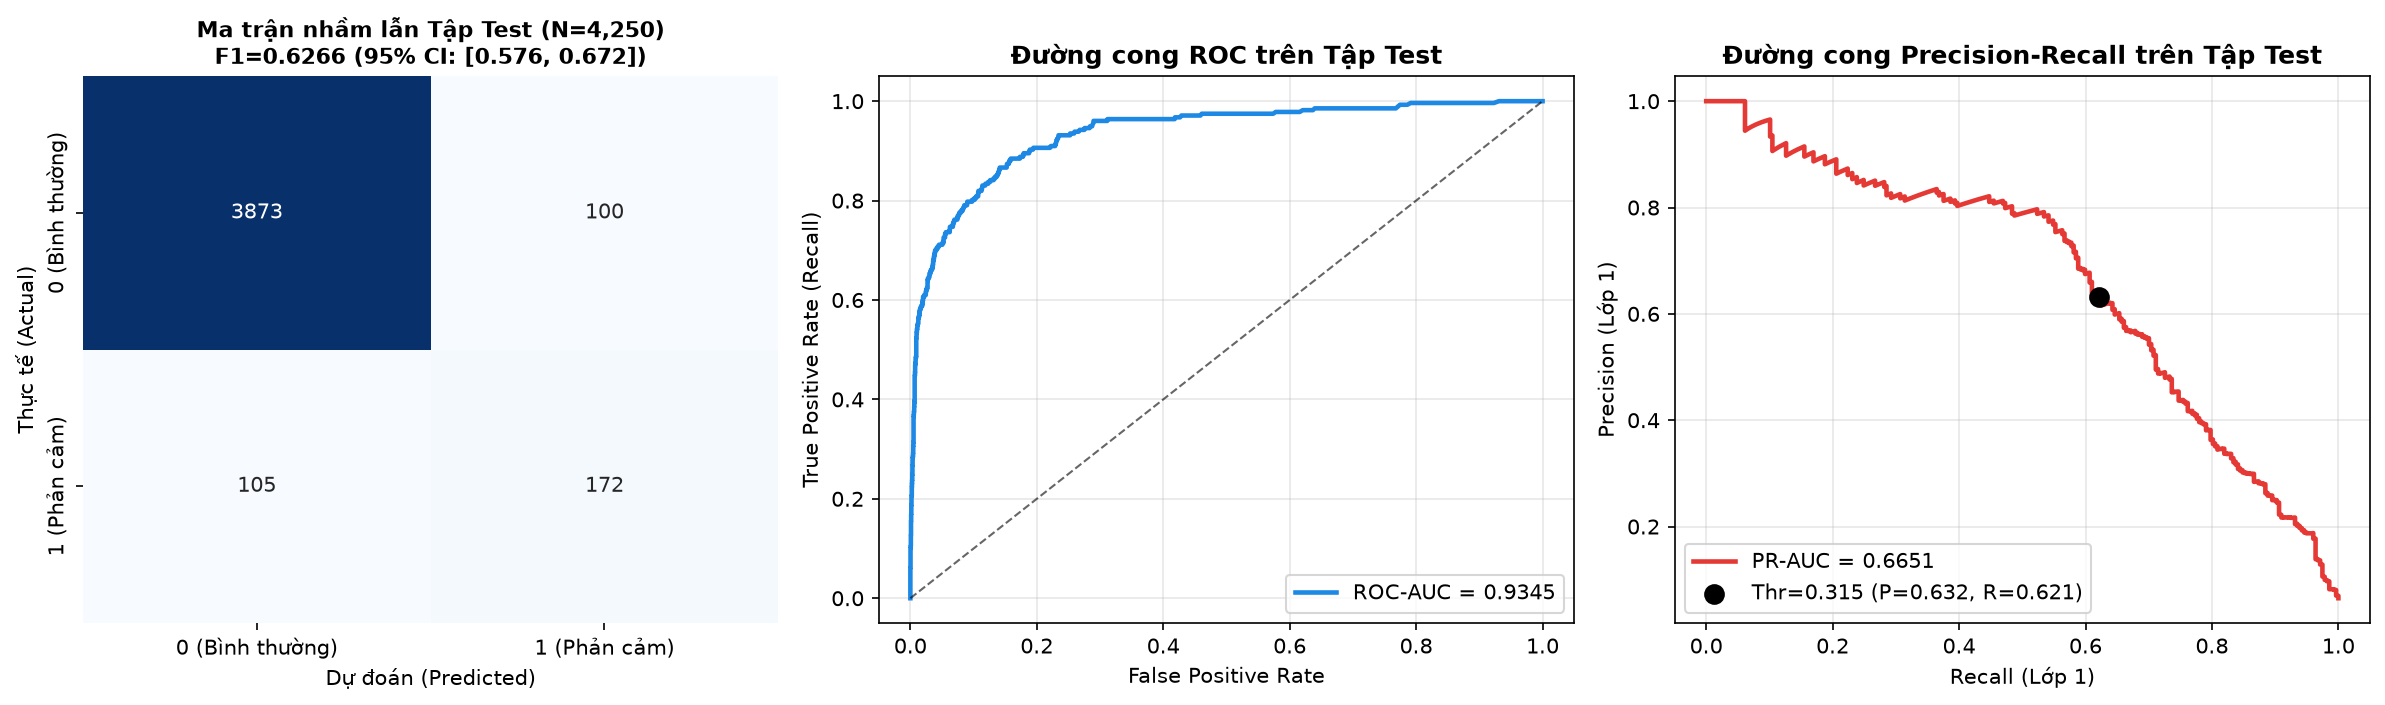

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

with open('reports/final_test_metrics.json', 'r', encoding='utf-8') as f:
    final_test = json.load(f)
with open('reports/final_test_ci.json', 'r', encoding='utf-8') as f:
    final_ci = json.load(f)

print(f"Thời điểm đánh giá Test duy nhất : {final_test['evaluated_once_at']}")
print(f"Mã băm SHA-256 file test.csv     : {final_test['test_file_sha256']}")
print(f"Ngưỡng quyết định ( từ Val )     : {final_test['threshold_used']}")

print('\n=== METRIC TRÊN TẬP TEST (N = 4,250) ===')
display(pd.DataFrame([final_test['metrics_at_tuned_threshold'], final_test['metrics_at_default_05']], index=['Tuned Threshold', 'Default 0.50']))

print('\n=== KHOẢNG TIN CẬY 95% BOOTSTRAP (1,000 LẦN) ===')
display(pd.DataFrame(final_ci).T.loc[['f1_pos', 'precision_pos', 'recall_pos', 'pr_auc', 'roc_auc']])
display(Image('reports/figures/P8_test_evaluation.png'))

## 2. Phân tích Lỗi (30 FP + 30 FN) & Phân loại Nguyên nhân Sai sót

=== BẢNG THỐNG KÊ NGUYÊN NHÂN LỖI TRÊN TẬP TEST ===


,cause,FN (Bỏ sót),FP (Báo động giả),total,pct
0,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,65,0,65,31.71
1,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,0,47,47,22.93
2,Nhãn gốc nhiễu hoặc ranh giới ngữ nghĩa mờ (No...,3,29,32,15.61
3,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,18,10,28,13.66
4,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,13,8,21,10.24
5,Chuỗi nhiều Hashtag / Khẩu hiệu đa chủ đề (Has...,6,6,12,5.85


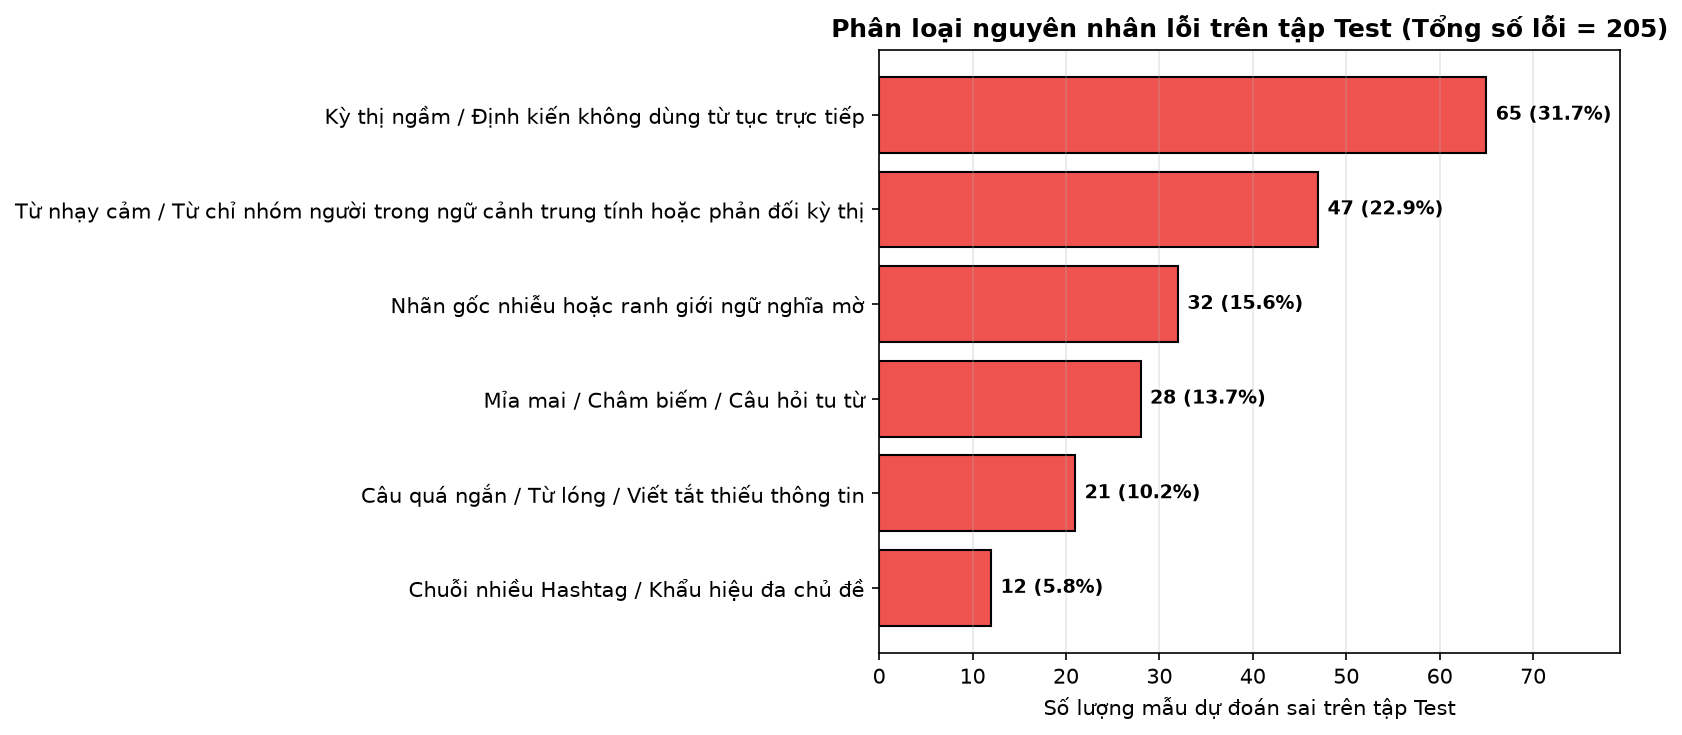

=== 10 Ví dụ Báo động giả (False Positives) có điểm cao nhất ===


,id,error_type,label,y_pred,score,cause,text_masked,text_clean_masked
0,1831,FP (Báo động giả),0,1,0.9831,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user is the prosecutor considering criminal c...,be the prosecutor consider criminal charge aga...
1,8500,FP (Báo động giả),0,1,0.9680,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,#obama #attacks #trump on #islamâ¦ #trump #di...,obama attack trump on islam trump dismantle hi...
2,21696,FP (Báo động giả),0,1,0.9611,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user trump is a liberal elite. textbook defin...,trump be a liberal elite textbook definition o...
3,25804,FP (Báo động giả),0,1,0.9567,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,"@user ali, spoke the #truth about white folks....",ali speak the truth about white folk period fa...
4,14162,FP (Báo động giả),0,1,0.9340,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,movie ð¥ review.... x-men apocalypse now #u...,movie review men apocalypse now uspresidential...
5,25493,FP (Báo động giả),0,1,0.9296,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user what if obama showed the same anger and ...,what if obama show the same anger and disgust ...
6,27935,FP (Báo động giả),0,1,0.9178,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user how did you slip through? you are a thr...,how do you slip through you be a threat to ame...
7,11879,FP (Báo động giả),0,1,0.9057,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,did you tweet those comments!? #bekindtoonea...,do you tweet those comment bekindtooneanother
8,28217,FP (Báo động giả),0,1,0.9046,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,@user @user @user everybody hates the white cr...,everybody hate the white crayon
9,27657,FP (Báo động giả),0,1,0.8846,Từ nhạy cảm / Từ chỉ nhóm người trong ngữ cảnh...,black f*****g rapping sexy women bihday nude,black f**k rap sexy woman bihday nude


=== 10 Ví dụ Bỏ sót (False Negatives) có điểm thấp nhất ===


,id,error_type,label,y_pred,score,cause,text_masked,text_clean_masked
30,2237,FN (Bỏ sót),1,0,0.0018,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,travelled for #canucks game sad and disappoint...,travel for canuck game sad and disappoint of o...
31,3468,FN (Bỏ sót),1,0,0.0040,Chuỗi nhiều Hashtag / Khẩu hiệu đa chủ đề (Has...,episode 6 of the guns for everyone #podcast is...,episode of the gun for everyone podcast be up ...
32,12337,FN (Bỏ sót),1,0,0.0043,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,@user care about #cjreform? follow me: i cover...,care about cjreform follow me i cover deathpen...
33,18747,FN (Bỏ sót),1,0,0.0043,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,i almost always trust brazilians,i almost always trust brazilian
34,13764,FN (Bỏ sót),1,0,0.0069,Câu quá ngắn / Từ lóng / Viết tắt thiếu thông ...,almost as as dad #5wordtrumplethinskin,almost a a dad wordtrumplethinskin
35,17764,FN (Bỏ sót),1,0,0.0075,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,@user @user @user #smileyong along with #ki...,smileyong along with kingconrad make me go thr...
36,1480,FN (Bỏ sót),1,0,0.0087,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,smh i cant take these one sided standards,smh i cant take these one side standard
37,8092,FN (Bỏ sót),1,0,0.0126,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,@user my story: how #race and have played a r...,my story how race and have play a role in my life
38,7244,FN (Bỏ sót),1,0,0.0139,Mỉa mai / Châm biếm / Câu hỏi tu từ (Sarcasm &...,pathetic fallacy? infantile ? just in case any...,pathetic fallacy infantile just in case anyone...
39,1275,FN (Bỏ sót),1,0,0.0144,Kỳ thị ngầm / Định kiến không dùng từ tục trực...,is a very profitable thing im #america,be a very profitable thing im america


In [3]:
causes_df = pd.read_csv('reports/tables/P8_error_causes.csv')
print('=== BẢNG THỐNG KÊ NGUYÊN NHÂN LỖI TRÊN TẬP TEST ===')
display(causes_df)
display(Image('reports/figures/P8_error_causes.png'))

errors_df = pd.read_csv('reports/tables/P8_errors.csv')
print('=== 10 Ví dụ Báo động giả (False Positives) có điểm cao nhất ===')
display(errors_df[errors_df['error_type'].str.startswith('FP')].head(10))
print('=== 10 Ví dụ Bỏ sót (False Negatives) có điểm thấp nhất ===')
display(errors_df[errors_df['error_type'].str.startswith('FN')].head(10))

## 3. Giải thích Mô hình (Top Trọng số) & Phân tích Thiên lệch Nhóm (Subgroup Bias)

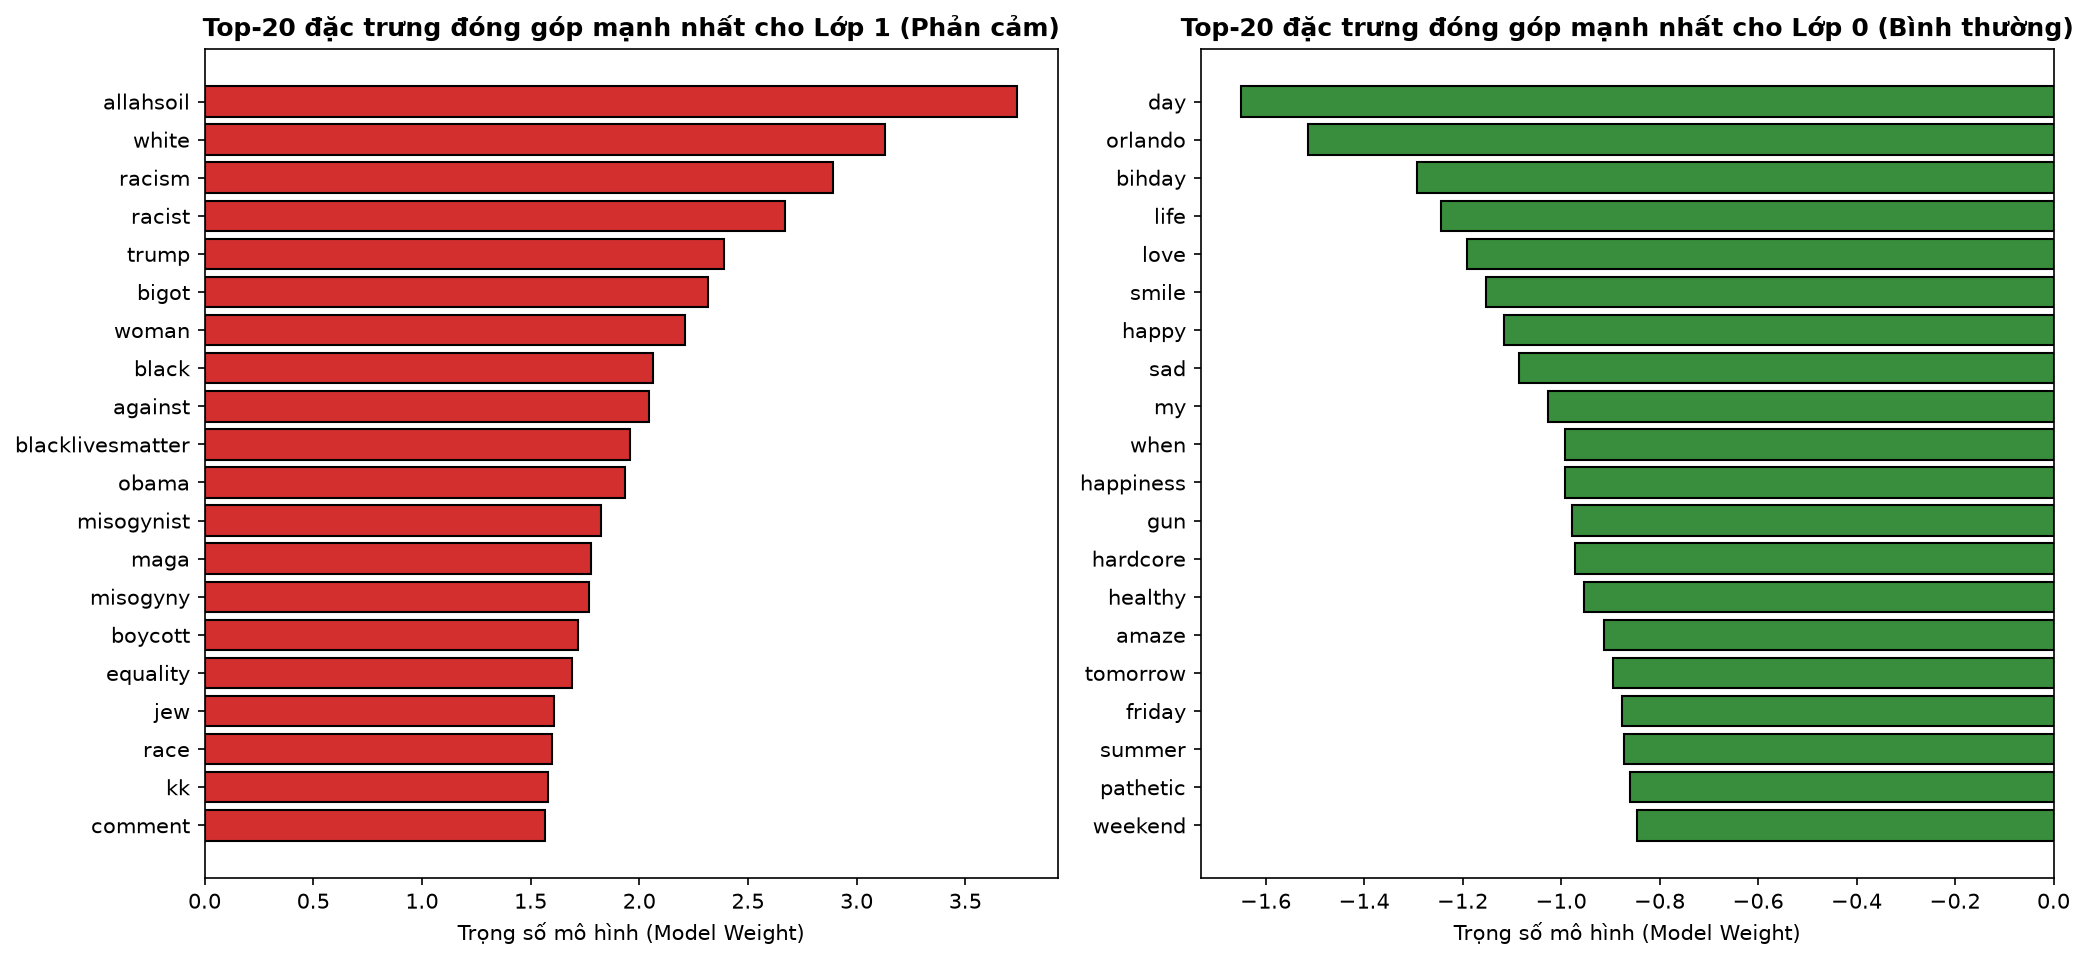

=== BẢNG KIỂM TRA THIÊN LỆCH: TỈ LỆ BÁO ĐỘNG GIẢ (FPR) THEO NHÓM TỪ NHẬN DIỆN ===


,subgroup,n_neg_tweets,n_false_positives,fpr_pct,mean_score
0,Toàn bộ mẫu Lớp 0 trên Test (Overall Baseline),3973,100,2.52,0.0401
1,"Giới tính / Phụ nữ (women, woman, girl, female)",100,4,4.00,0.0604
2,"Chủng tộc / Màu da (black, white, race, african)",46,14,30.43,0.2469
3,"Tôn giáo (muslim, islam, jewish, christian, god)",20,4,20.00,0.2108
4,"Xu hướng tính dục (gay, lgbt, queer)",27,2,7.41,0.0816
5,"Chính trị (trump, obama, clinton, liberal, gop)",66,23,34.85,0.3026


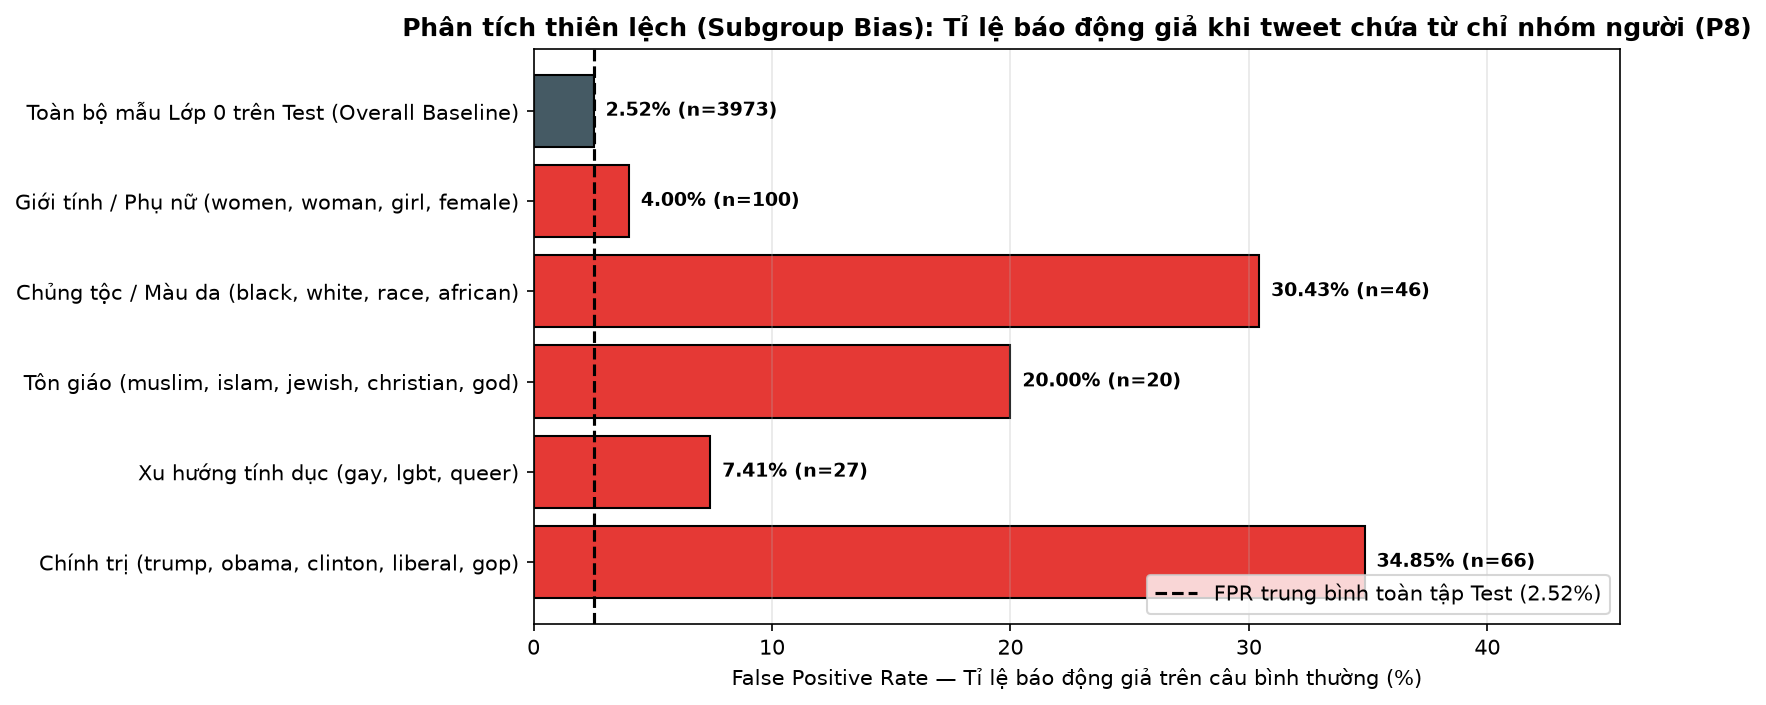

In [4]:
coef_df = pd.read_csv('reports/tables/P8_top_coefficients.csv')
display(Image('reports/figures/P8_feature_importance.png'))

bias_df = pd.read_csv('reports/tables/P8_subgroup_bias.csv')
print('=== BẢNG KIỂM TRA THIÊN LỆCH: TỈ LỆ BÁO ĐỘNG GIẢ (FPR) THEO NHÓM TỪ NHẬN DIỆN ===')
display(bias_df)
display(Image('reports/figures/P8_subgroup_bias.png'))

### Nhận xét & Hạn chế 
- Trên tập Test độc lập ($N = 4,250$), mô hình đạt **F1 lớp dương = 0.6266** (95% CI: **[0.5764, 0.6716]**), **Precision = 0.6324**, **Recall = 0.6209**, **PR-AUC = 0.6651** và **ROC-AUC = 0.9345**.
- **Nguyên nhân lỗi chính:** (1) Đối với *False Negatives (Bỏ sót)*, phần lớn là các câu kỳ thị ngầm, định kiến hoặc châm biếm không sử dụng từ tục trực tiếp; (2) Đối với *False Positives (Báo động giả)*, lỗi xảy ra khi câu bình thường chứa các từ chỉ nhóm nhạy cảm (`women`, `black`, `white`, `trump`, `racist`) trong ngữ cảnh đưa tin hoặc phản đối phân biệt đối xử.
- **Phân tích thiên lệch (Subgroup Bias):** Tỉ lệ báo động giả (FPR) trên các câu bình thường có nhắc đến từ chỉ chủng tộc, tôn giáo hoặc giới tính cao hơn mức FPR trung bình toàn tập Test — đây là hạn chế kinh điển của các mô hình dựa trên tần suất từ vựng cần được lưu ý khi triển khai thực tế.